# Add Kerala-style conditioning factors to the Sri Lanka dataset

This notebook takes `training_table_with_rainfall.csv` (already built by
`07h_Merge_Sri_Lanka_districts.ipynb`) and adds the factors that exist in the
Kerala dataset (`07b2_Kerala_dataset_builder_New.ipynb`) but are still missing
for Sri Lanka:

| Factor family | Kerala columns | Sri Lanka status |
|---|---|---|
| Terrain/hydrology | elev, slope, aspect, planc, profc, twi, spi | already present (renamed) |
| SoilGrids 2.0 | clay, sand, soc, bdod | **missing -> added here** |
| ESA WorldCover 2021 | landcover | **missing -> added here** |
| GLiM lithology | geologi | **missing -> added here** |
| distance to river/road | excluded from Kerala | Sri Lanka already has these (kept as extra) |
| rainfall windows | not in Kerala | Sri Lanka already has these (kept as extra) |

Because the Sri Lanka points already exist (NBRO district extractions), we do
**not** rebuild a full 30 m analysis grid the way the Kerala notebook does.
We simply sample the same open data sources (SoilGrids, ESA WorldCover, GLiM)
directly at the existing point coordinates. This is functionally identical to
what the Kerala notebook does, just without the extra step of writing an
aligned country-wide raster mosaic (which Kerala only needed because it also
produces prediction-ready wall-to-wall factor maps).

In [1]:
from pathlib import Path
from datetime import datetime, timezone
import json
import math
import time
import warnings

import numpy as np
import pandas as pd
import geopandas as gpd
import rasterio
from rasterio.merge import merge as rio_merge
from rasterio.warp import transform as warp_transform
from shapely.geometry import Point
import requests

warnings.filterwarnings("ignore", category=UserWarning)
print("GeoPandas:", gpd.__version__)
print("Rasterio :", rasterio.__version__)

GeoPandas: 1.1.4
Rasterio : 1.4.4


In [2]:
# 2 -- Configuration
PROJECT_ROOT = Path.cwd().resolve().parent

DATA_DIR = PROJECT_ROOT / "data"
DATA_PROCESSED = DATA_DIR / "processed"
RAW_DIR = DATA_DIR / "raw" / "Sri_Lanka_dataset"

SOIL_RAW_DIR = RAW_DIR / "soilgrids"
WORLDCOVER_DIR = RAW_DIR / "worldcover"
GEOLOGY_DIR = RAW_DIR / "geology"

for folder in [DATA_PROCESSED, SOIL_RAW_DIR, WORLDCOVER_DIR, GEOLOGY_DIR]:
    folder.mkdir(parents=True, exist_ok=True)

INPUT_CSV = DATA_PROCESSED / "training_table_with_rainfall.csv"
BBOX_BUFFER_DEG = 0.05  # small pad around the point cloud so raster/vector pulls aren't edge-clipped

print("Project root:", PROJECT_ROOT)
print("Input table :", INPUT_CSV, "| exists:", INPUT_CSV.exists())

Project root: D:\PROJECTS\Landslide_prediction
Input table : D:\PROJECTS\Landslide_prediction\data\processed\training_table_with_rainfall.csv | exists: True


In [3]:
# 3 -- Load Sri Lanka points and build the bounding box to fetch factor data for
sl = pd.read_csv(INPUT_CSV)

sl_gdf = gpd.GeoDataFrame(
    sl,
    geometry=[Point(xy) for xy in zip(sl["longitude"], sl["latitude"])],
    crs="EPSG:4326",
)

minx, miny, maxx, maxy = sl_gdf.total_bounds
minx -= BBOX_BUFFER_DEG
miny -= BBOX_BUFFER_DEG
maxx += BBOX_BUFFER_DEG
maxy += BBOX_BUFFER_DEG

print("Points:", len(sl_gdf))
print(f"Bounding box (buffered): lon [{minx:.4f}, {maxx:.4f}], lat [{miny:.4f}, {maxy:.4f}]")

Points: 1463
Bounding box (buffered): lon [80.1195, 81.2897], lat [6.5397, 7.6276]


## 4. SoilGrids 2.0 -- clay, sand, soc, bdod (same as Kerala)

In [4]:
# 4a -- Download SoilGrids 0-5cm layers for the Sri Lanka bounding box
SOILGRIDS_VARS = {
    'clay': 'clay_0-5cm_mean',
    'sand': 'sand_0-5cm_mean',
    'soc':  'soc_0-5cm_mean',      # soil organic carbon
    'bdod': 'bdod_0-5cm_mean',     # bulk density
}

SOIL_PATHS = {}

for name, layer in SOILGRIDS_VARS.items():
    out_path = SOIL_RAW_DIR / f'soilgrids_{name}.tif'
    SOIL_PATHS[name] = out_path
    if out_path.exists():
        print(f'{name}: already downloaded')
        continue
    url = (
        f"https://maps.isric.org/mapserv?map=/map/{layer.split('_')[0]}.map"
        f"&SERVICE=WCS&VERSION=2.0.1&REQUEST=GetCoverage"
        f"&COVERAGEID={layer}&FORMAT=GEOTIFF_INT16"
        f"&SUBSET=X({minx},{maxx})&SUBSET=Y({miny},{maxy})&SUBSETTINGCRS=EPSG:4326"
    )
    r = requests.get(url, timeout=120)
    r.raise_for_status()
    out_path.write_bytes(r.content)
    print(f'{name}: saved {out_path}')

clay: saved D:\PROJECTS\Landslide_prediction\data\raw\Sri_Lanka_dataset\soilgrids\soilgrids_clay.tif
sand: saved D:\PROJECTS\Landslide_prediction\data\raw\Sri_Lanka_dataset\soilgrids\soilgrids_sand.tif
soc: saved D:\PROJECTS\Landslide_prediction\data\raw\Sri_Lanka_dataset\soilgrids\soilgrids_soc.tif
bdod: saved D:\PROJECTS\Landslide_prediction\data\raw\Sri_Lanka_dataset\soilgrids\soilgrids_bdod.tif


In [ ]:
# 4b  Raster point-sampling helper (identical logic to the Kerala notebook)
def sample_raster_at_points(raster_path, points_gdf, band=1):
    raster_path = Path(raster_path)
    with rasterio.open(raster_path) as src:
        pts = points_gdf.to_crs(src.crs) if points_gdf.crs != src.crs else points_gdf
        coords = [(geom.x, geom.y) for geom in pts.geometry]
        values = np.array([v[band - 1] for v in src.sample(coords)], dtype="float64")
        if src.nodata is not None:
            values[values == src.nodata] = np.nan
        values[~np.isfinite(values)] = np.nan
    return values

# 4c  Sample soil rasters directly at the existing SL points and apply SoilGrids unit conversions
soil_factor_rasters = {
    "clay": {"path": SOIL_PATHS["clay"], "divisor": 10.0, "unit": "%"},
    "sand": {"path": SOIL_PATHS["sand"], "divisor": 10.0, "unit": "%"},
    "soc":  {"path": SOIL_PATHS["soc"],  "divisor": 10.0, "unit": "g/kg"},
    "bdod": {"path": SOIL_PATHS["bdod"], "divisor": 100.0, "unit": "kg/dm3"},
}

for name, info in soil_factor_rasters.items():
    raw = sample_raster_at_points(info["path"], sl_gdf)
    sl_gdf[name] = raw / info["divisor"]
    print(f"{name:6s}: {sl_gdf[name].notna().sum():,}/{len(sl_gdf):,} valid ({info['unit']})")

clay  : 1,463/1,463 valid (%)
sand  : 1,463/1,463 valid (%)
soc   : 1,463/1,463 valid (g/kg)
bdod  : 1,463/1,463 valid (kg/dm3)


## 5. ESA WorldCover 2021 -- landcover (same as Kerala)

In [6]:
# 5a -- Work out which 3x3 degree WorldCover tiles cover the Sri Lanka bbox
def worldcover_tile_name(lat, lon):
    lat_base = math.floor(lat / 3) * 3
    lon_base = math.floor(lon / 3) * 3
    lat_prefix = "N" if lat_base >= 0 else "S"
    lon_prefix = "E" if lon_base >= 0 else "W"
    return f"{lat_prefix}{abs(lat_base):02d}{lon_prefix}{abs(lon_base):03d}"

tiles = []
lat = math.floor(miny / 3) * 3
while lat <= maxy:
    lon = math.floor(minx / 3) * 3
    while lon <= maxx:
        tiles.append(worldcover_tile_name(lat + 0.01, lon + 0.01))
        lon += 3
    lat += 3
tiles = sorted(set(tiles))
print("WorldCover tiles needed:", tiles)

WorldCover tiles needed: ['N06E078', 'N06E081']


In [7]:
# 5b -- Download the tiles
downloaded_tiles = []

for tile in tiles:
    filename = f"ESA_WorldCover_10m_2021_v200_{tile}_Map.tif"
    url = f"https://esa-worldcover.s3.eu-central-1.amazonaws.com/v200/2021/map/{filename}"
    out_path = WORLDCOVER_DIR / filename

    if out_path.exists():
        print(tile, "already downloaded")
        downloaded_tiles.append(out_path)
        continue

    print("Downloading:", tile)
    response = requests.get(url, timeout=300)
    if response.status_code == 200:
        out_path.write_bytes(response.content)
        downloaded_tiles.append(out_path)
        print("  saved")
    else:
        print("  not available:", response.status_code)

Downloading: N06E078
  saved
Downloading: N06E081
  saved


In [8]:
# 5c -- Merge tiles into a single in-memory mosaic, then sample directly at the SL points
srcs = [rasterio.open(p) for p in downloaded_tiles]
mosaic, mosaic_transform = rio_merge(srcs, bounds=(minx, miny, maxx, maxy))
mosaic_meta = srcs[0].meta.copy()
mosaic_meta.update(
    height=mosaic.shape[1],
    width=mosaic.shape[2],
    transform=mosaic_transform,
)
for s in srcs:
    s.close()

LANDCOVER_MOSAIC = WORLDCOVER_DIR / "sri_lanka_worldcover_mosaic.tif"
with rasterio.open(LANDCOVER_MOSAIC, "w", **mosaic_meta) as dst:
    dst.write(mosaic)

sl_gdf["landcover"] = sample_raster_at_points(LANDCOVER_MOSAIC, sl_gdf)
sl_gdf.loc[sl_gdf["landcover"] == 0, "landcover"] = np.nan  # WorldCover nodata = 0
print(f"landcover: {sl_gdf['landcover'].notna().sum():,}/{len(sl_gdf):,} valid")

worldcover_classes = {
    10: "Tree cover", 20: "Shrubland", 30: "Grassland", 40: "Cropland",
    50: "Built-up", 60: "Bare / sparse vegetation", 70: "Snow and ice",
    80: "Permanent water", 90: "Herbaceous wetland", 95: "Mangroves", 100: "Moss and lichen",
}
print(sl_gdf["landcover"].dropna().astype(int).map(worldcover_classes).value_counts())

landcover: 1,463/1,463 valid
landcover
Tree cover         1198
Grassland           187
Cropland             42
Permanent water      19
Built-up             17
Name: count, dtype: int64


## 6. GLiM lithology -- geologi (same as Kerala)

In [9]:
# 6a -- Download GLiM lithology polygons for the Sri Lanka bbox
GEOLOGY_RAW_PATH = GEOLOGY_DIR / "sri_lanka_glim_geology.gpkg"

GLIM_URL = (
    "https://services8.arcgis.com/4KhTMTZ1x0f76DSg/ArcGIS/rest/services/"
    "GLiM_Niveau_I/FeatureServer/1/query"
)

if GEOLOGY_RAW_PATH.exists():
    print("Loading saved Sri Lanka geology...")
    geology_sl = gpd.read_file(GEOLOGY_RAW_PATH)
else:
    print("Downloading GLiM geology for Sri Lanka...")
    geometry_string = f"{minx},{miny},{maxx},{maxy}"
    all_features = []
    offset = 0
    batch_size = 1000

    while True:
        params = {
            "where": "1=1",
            "geometry": geometry_string,
            "geometryType": "esriGeometryEnvelope",
            "inSR": "4326",
            "outSR": "4326",
            "spatialRel": "esriSpatialRelIntersects",
            "outFields": "OBJECTID,Litho,xx_Description",
            "returnGeometry": "true",
            "resultOffset": offset,
            "resultRecordCount": batch_size,
            "f": "geojson",
        }
        response = requests.get(GLIM_URL, params=params, timeout=120)
        response.raise_for_status()
        data = response.json()
        features = data.get("features", [])
        if not features:
            break
        all_features.extend(features)
        print(f"Downloaded {len(all_features)} polygons...")
        if len(features) < batch_size:
            break
        offset += batch_size

    if not all_features:
        raise RuntimeError("No geology features were returned.")

    geology_sl = gpd.GeoDataFrame.from_features(all_features, crs="EPSG:4326")
    geology_sl = geology_sl[["OBJECTID", "Litho", "xx_Description", "geometry"]].copy()
    geology_sl.to_file(GEOLOGY_RAW_PATH, layer="geology", driver="GPKG")
    print("Saved:", GEOLOGY_RAW_PATH)

print("\nNumber of geology polygons:", len(geology_sl))
print(geology_sl["xx_Description"].value_counts())

Downloaded 317 polygons...
Saved: D:\PROJECTS\Landslide_prediction\data\raw\Sri_Lanka_dataset\geology\sri_lanka_glim_geology.gpkg

Number of geology polygons: 317
xx_Description
Siliciclastic sedimentary rocks    104
Metamorphics                        98
Acid plutonic rocks                 69
Carbonate sedimentary rocks         34
Water Bodies                         7
Unconsolidated sediments             3
Intermediate plutonic rocks          1
Basic plutonic rocks                 1
Name: count, dtype: int64


In [10]:
# 6b -- Encode geology classes exactly like the Kerala notebook (categorical code + name)
geology_sl["geology_name"] = geology_sl["xx_Description"].astype(str).str.strip()
geology_sl = geology_sl[geology_sl["geology_name"] != "No Data"].copy()

geology_classes = sorted(geology_sl["geology_name"].dropna().unique())
geology_mapping = {name: i + 1 for i, name in enumerate(geology_classes)}
geology_sl["geologi"] = geology_sl["geology_name"].map(geology_mapping)

geology_legend = pd.DataFrame(
    {"geologi": list(geology_mapping.values()), "geology_name": list(geology_mapping.keys())}
)
GEOLOGY_LEGEND_PATH = DATA_PROCESSED / "sri_lanka_geology_legend.csv"
geology_legend.to_csv(GEOLOGY_LEGEND_PATH, index=False)
print("Saved:", GEOLOGY_LEGEND_PATH)

Saved: D:\PROJECTS\Landslide_prediction\data\processed\sri_lanka_geology_legend.csv


In [11]:
# 6c -- Spatial join: attach geology class to each Sri Lanka point
sl_with_id = sl_gdf.reset_index().rename(columns={"index": "point_id"})
geology_for_join = geology_sl[["geologi", "geology_name", "geometry"]].to_crs(sl_gdf.crs)

geology_join = gpd.sjoin(sl_with_id, geology_for_join, how="left", predicate="within")
geology_join = geology_join.sort_values("point_id").drop_duplicates(subset="point_id")

sl_gdf["geologi"] = sl_gdf.index.to_series().map(geology_join.set_index("point_id")["geologi"])
sl_gdf["geology_name"] = sl_gdf.index.to_series().map(geology_join.set_index("point_id")["geology_name"])

print("Valid geology:", sl_gdf["geologi"].notna().sum(), "/", len(sl_gdf))
print(sl_gdf["geology_name"].value_counts(dropna=False))

Valid geology: 1463 / 1463
geology_name
Metamorphics                       1300
Siliciclastic sedimentary rocks      90
Acid plutonic rocks                  44
Carbonate sedimentary rocks          28
Intermediate plutonic rocks           1
Name: count, dtype: int64


In [2]:
from pathlib import Path
import geopandas as gpd
import matplotlib.pyplot as plt

# Existing saved geology file
PROJECT_ROOT = Path.cwd().resolve().parent

GEOLOGY_RAW_PATH = (
    PROJECT_ROOT
    / "data"
    / "raw"
    / "Sri_Lanka_dataset"
    / "geology"
    / "sri_lanka_glim_geology.gpkg"
)

print("Geology file exists:", GEOLOGY_RAW_PATH.exists())

# Load already downloaded GLiM polygons
geology_sl = gpd.read_file(GEOLOGY_RAW_PATH)

# Prepare readable geology names
geology_sl["geology_name"] = (
    geology_sl["xx_Description"]
    .astype(str)
    .str.strip()
)

# Remove No Data polygons
geology_sl = geology_sl[
    geology_sl["geology_name"] != "No Data"
].copy()

print("Number of geology polygons:", len(geology_sl))
print(geology_sl["geology_name"].value_counts())

Geology file exists: True
Number of geology polygons: 317
geology_name
Siliciclastic sedimentary rocks    104
Metamorphics                        98
Acid plutonic rocks                 69
Carbonate sedimentary rocks         34
Water Bodies                         7
Unconsolidated sediments             3
Intermediate plutonic rocks          1
Basic plutonic rocks                 1
Name: count, dtype: int64


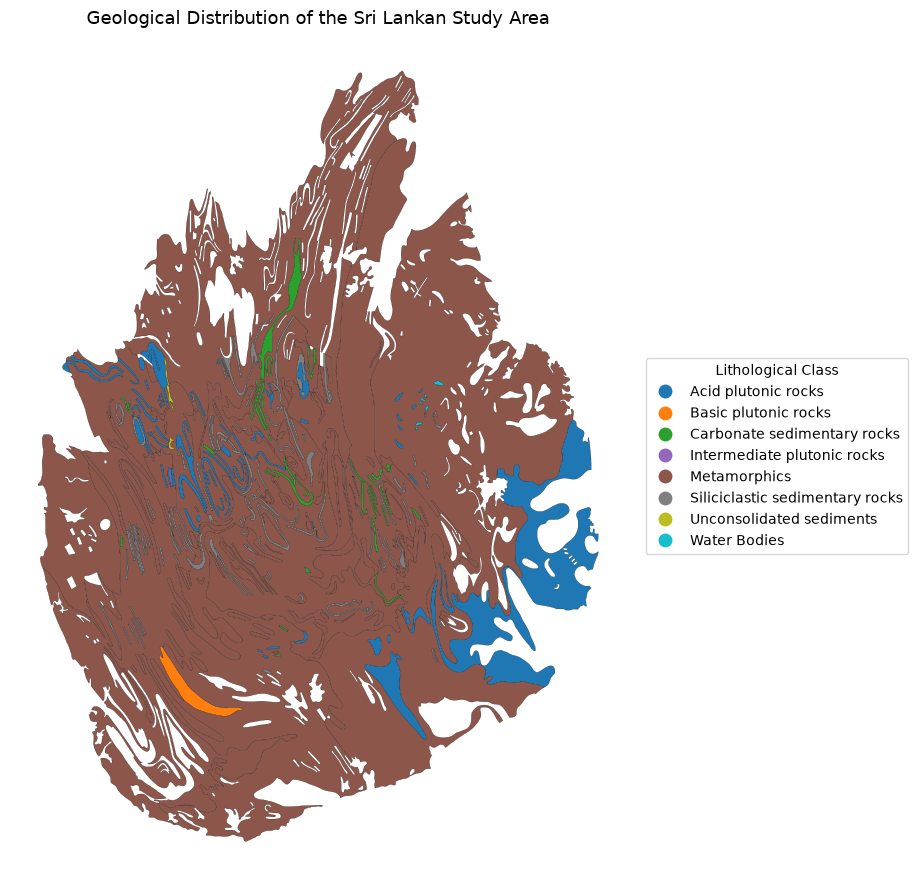

In [6]:
fig, ax = plt.subplots(figsize=(10, 9))

geology_sl.plot(
    column="geology_name",
    categorical=True,
    legend=True,
    ax=ax,
    edgecolor="black",
    linewidth=0.15,
    legend_kwds={
        "title": "Lithological Class",
        "loc": "center left",
        "bbox_to_anchor": (1.02, 0.5)
    }
)

ax.set_title(
    "Geological Distribution of the Sri Lankan Study Area",
    fontsize=13
)

ax.set_axis_off()

plt.tight_layout()

plt.savefig(
    "sri_lanka_geology_map.png",
    dpi=300,
    bbox_inches="tight"
)

plt.show()

Loaded geology polygons: 317
Geology CRS: EPSG:4326

Available geology classes:
geology_name
Siliciclastic sedimentary rocks    104
Metamorphics                        98
Acid plutonic rocks                 69
Carbonate sedimentary rocks         34
Water Bodies                         7
Unconsolidated sediments             3
Intermediate plutonic rocks          1
Basic plutonic rocks                 1
Name: count, dtype: int64

AOI columns:
Index(['adm2_name', 'adm2_name1', 'adm2_name2', 'adm2_name3', 'adm2_pcode',
       'adm1_name', 'adm1_name1', 'adm1_name2', 'adm1_name3', 'adm1_pcode',
       'adm0_name', 'adm0_name1', 'adm0_name2', 'adm0_name3', 'adm0_pcode',
       'valid_on', 'valid_to', 'area_sqkm', 'version', 'lang', 'lang1',
       'lang2', 'lang3', 'center_lat', 'center_lon', 'geometry'],
      dtype='str')

Selected target districts:
['Kandy', 'Nuwara Eliya', 'Badulla', 'Kegalle']

AOI CRS: EPSG:4326
Geology CRS: EPSG:4326

Geology polygons after clipping: 192

Geology clas

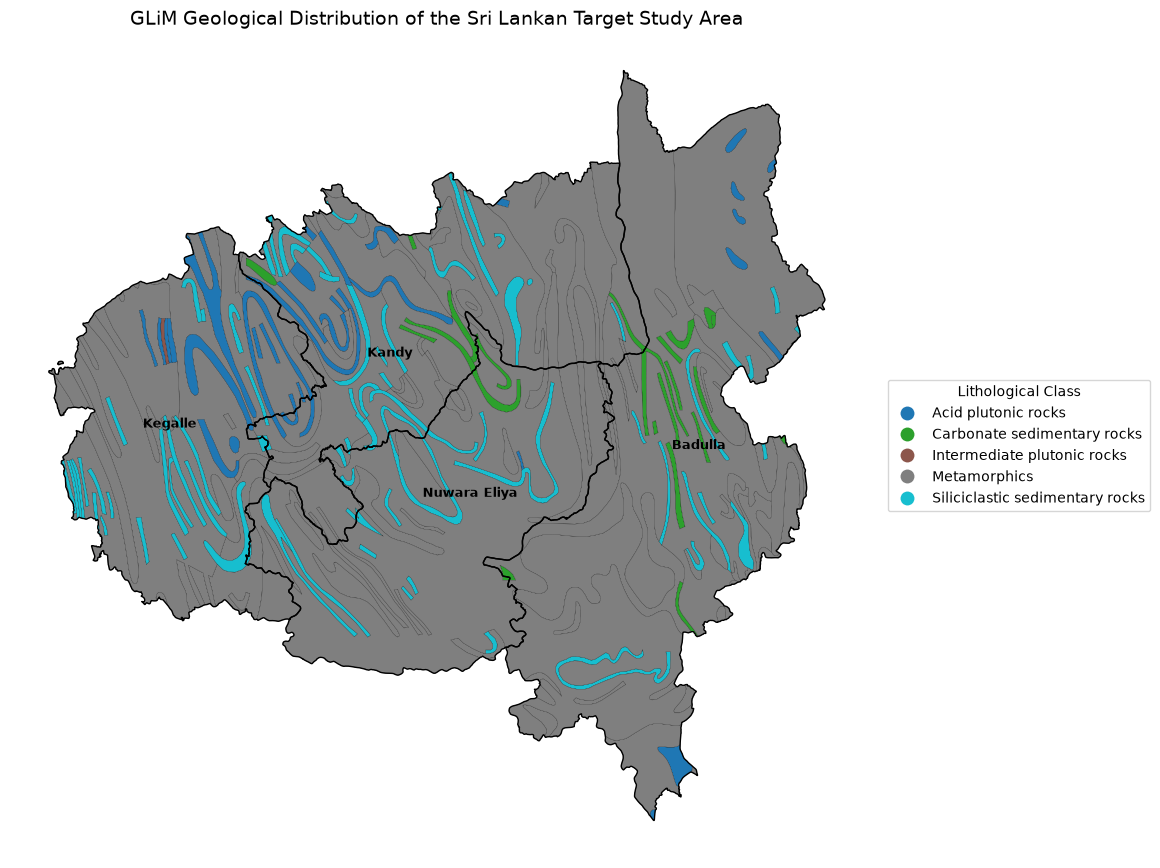


Saved figure to:
D:\PROJECTS\Landslide_prediction\sri_lanka_geology_target_districts.png


In [5]:
from pathlib import Path
import geopandas as gpd
import matplotlib.pyplot as plt

# ---------------------------------------------------------
# 1. Project paths
# ---------------------------------------------------------

PROJECT_ROOT = Path.cwd().resolve().parent

GEOLOGY_RAW_PATH = (
    PROJECT_ROOT
    / "data"
    / "raw"
    / "Sri_Lanka_dataset"
    / "geology"
    / "sri_lanka_glim_geology.gpkg"
)

AOI_PATH = (
    PROJECT_ROOT
    / "data"
    / "processed"
    / "aoi.gpkg"
)

# ---------------------------------------------------------
# 2. Load existing geology data
# ---------------------------------------------------------

geology_sl = gpd.read_file(GEOLOGY_RAW_PATH)

print("Loaded geology polygons:", len(geology_sl))
print("Geology CRS:", geology_sl.crs)

# Create readable geology names
geology_sl["geology_name"] = (
    geology_sl["xx_Description"]
    .astype(str)
    .str.strip()
)

# Remove No Data polygons
geology_sl = geology_sl[
    geology_sl["geology_name"] != "No Data"
].copy()

print("\nAvailable geology classes:")
print(geology_sl["geology_name"].value_counts())

# ---------------------------------------------------------
# 3. Load study-area districts
# ---------------------------------------------------------

aoi = gpd.read_file(
    AOI_PATH,
    layer="districts"
)

print("\nAOI columns:")
print(aoi.columns)

# ---------------------------------------------------------
# 4. Keep only the four target districts
# ---------------------------------------------------------

TARGET_DISTRICTS = [
    "Kandy",
    "Nuwara Eliya",
    "Kegalle",
    "Badulla"
]

aoi = aoi[
    aoi["adm2_name"].isin(TARGET_DISTRICTS)
].copy()

print("\nSelected target districts:")
print(aoi["adm2_name"].tolist())

# ---------------------------------------------------------
# 5. Match CRS
# ---------------------------------------------------------

if aoi.crs != geology_sl.crs:
    aoi = aoi.to_crs(geology_sl.crs)

print("\nAOI CRS:", aoi.crs)
print("Geology CRS:", geology_sl.crs)

# ---------------------------------------------------------
# 6. Clip geology to the target study area
# ---------------------------------------------------------

geology_aoi = gpd.clip(
    geology_sl,
    aoi
)

print("\nGeology polygons after clipping:", len(geology_aoi))

print("\nGeology classes inside target districts:")
print(geology_aoi["geology_name"].value_counts())

# ---------------------------------------------------------
# 7. Plot geology map
# ---------------------------------------------------------

fig, ax = plt.subplots(figsize=(11, 9))

geology_aoi.plot(
    column="geology_name",
    categorical=True,
    legend=True,
    ax=ax,
    edgecolor="black",
    linewidth=0.15,
    legend_kwds={
        "title": "Lithological Class",
        "loc": "center left",
        "bbox_to_anchor": (1.02, 0.5)
    }
)

# Plot district boundaries
aoi.boundary.plot(
    ax=ax,
    edgecolor="black",
    linewidth=1.0
)

# Optional: add district labels
label_points = aoi.copy()
label_points["geometry"] = label_points.geometry.representative_point()

for _, row in label_points.iterrows():
    ax.text(
        row.geometry.x,
        row.geometry.y,
        row["adm2_name"],
        fontsize=9,
        ha="center",
        va="center",
        fontweight="bold"
    )

ax.set_title(
    "GLiM Geological Distribution of the Sri Lankan Target Study Area",
    fontsize=14
)

ax.set_axis_off()

plt.tight_layout()

# ---------------------------------------------------------
# 8. Save figure
# ---------------------------------------------------------

OUTPUT_PATH = (
    PROJECT_ROOT
    / "sri_lanka_geology_target_districts.png"
)

plt.savefig(
    OUTPUT_PATH,
    dpi=300,
    bbox_inches="tight"
)

plt.show()

print("\nSaved figure to:")
print(OUTPUT_PATH)

## 7. Harmonize column names with Kerala and save the extended table

Kerala uses `planc`/`profc`; Sri Lanka currently uses `plan_curv`/`profile_curv`.
We add Kerala-named aliases so the two tables share an identical factor schema
and can be concatenated for pooled/transfer modelling, while keeping Sri
Lanka's extra columns (`dist_to_river`, `dist_to_road`, `rain_*`, `district`)
since they are useful additions Kerala's version doesn't have.

In [12]:
# 7a -- Add Kerala-named aliases for the terrain columns Sri Lanka already has
sl_gdf["planc"] = sl_gdf["plan_curv"]
sl_gdf["profc"] = sl_gdf["profile_curv"]

continuous_factor_columns = [
    "elev", "slope", "aspect", "planc", "profc", "twi", "spi",   # terrain (already had these)
    "clay", "sand", "soc", "bdod",                                # soil (added here)
]
categorical_factor_columns = ["landcover", "geologi"]             # added here

model_factor_columns = continuous_factor_columns + categorical_factor_columns

extra_sl_columns = [
    "dist_to_river", "dist_to_road",
    "rain_1d", "rain_3d", "rain_7d", "rain_15d", "rain_30d",
]

print("Continuous factors:", continuous_factor_columns)
print("Categorical factors:", categorical_factor_columns)
print("Extra Sri Lanka-only columns kept:", extra_sl_columns)

Continuous factors: ['elev', 'slope', 'aspect', 'planc', 'profc', 'twi', 'spi', 'clay', 'sand', 'soc', 'bdod']
Categorical factors: ['landcover', 'geologi']
Extra Sri Lanka-only columns kept: ['dist_to_river', 'dist_to_road', 'rain_1d', 'rain_3d', 'rain_7d', 'rain_15d', 'rain_30d']


In [13]:
# 7b -- Quality-control report (mirrors the Kerala notebook's QC cell)
report_columns = ["label", "country", "district", "source_dataset"] + model_factor_columns + extra_sl_columns

print("Rows:", len(sl_gdf))
print("\nClass balance:")
print(sl_gdf["label"].value_counts())
print("\nMissing values (%):")
print((sl_gdf[report_columns].isna().mean() * 100).round(2))

Rows: 1463

Class balance:
label
1    732
0    731
Name: count, dtype: int64

Missing values (%):
label             0.00
country           0.00
district          0.00
source_dataset    0.00
elev              0.00
slope             0.00
aspect            0.00
planc             0.00
profc             0.00
twi               0.00
spi               0.00
clay              0.00
sand              0.00
soc               0.00
bdod              0.00
landcover         0.00
geologi           0.00
dist_to_river     0.00
dist_to_road      0.00
rain_1d           0.07
rain_3d           0.07
rain_7d           0.07
rain_15d          0.07
rain_30d          0.07
dtype: float64


In [14]:
# 7c -- Save the extended Sri Lanka dataset (same style as Kerala's training_table_kerala_extended.csv)
FINAL_COLUMNS = [
    "label", "country", "source_dataset", "district",
    "x", "y", "longitude", "latitude",
] + model_factor_columns + extra_sl_columns

FINAL_CSV = DATA_PROCESSED / "training_table_sri_lanka_kerala_factors.csv"
FINAL_PARQUET = DATA_PROCESSED / "training_table_sri_lanka_kerala_factors.parquet"

out_df = sl_gdf[FINAL_COLUMNS].copy()
out_df.to_csv(FINAL_CSV, index=False, encoding="utf-8-sig")
out_df.to_parquet(FINAL_PARQUET, index=False)

print("Saved CSV    :", FINAL_CSV)
print("Saved Parquet:", FINAL_PARQUET)
print("Shape        :", out_df.shape)

Saved CSV    : D:\PROJECTS\Landslide_prediction\data\processed\training_table_sri_lanka_kerala_factors.csv
Saved Parquet: D:\PROJECTS\Landslide_prediction\data\processed\training_table_sri_lanka_kerala_factors.parquet
Shape        : (1463, 28)


In [15]:
# 7d -- Reproducibility manifest (mirrors kerala_dataset_manifest.json)
manifest = {
    "created_utc": datetime.now(timezone.utc).isoformat(),
    "total_samples": int(len(sl_gdf)),
    "districts": sl_gdf["district"].value_counts().to_dict(),
    "continuous_factors": continuous_factor_columns,
    "categorical_factors": categorical_factor_columns,
    "extra_columns_not_in_kerala": extra_sl_columns,
    "soilgrids_product": "SoilGrids 2.0",
    "soilgrids_depth": "0-5 cm mean",
    "soilgrids_native_resolution_m": 250,
    "worldcover_product": "ESA WorldCover 2021 v200",
    "worldcover_native_resolution_m": 10,
    "worldcover_tiles_used": tiles,
    "geology_product": "Global Lithological Map (GLiM)",
    "bbox_used_for_downloads": {"minx": minx, "miny": miny, "maxx": maxx, "maxy": maxy},
}

MANIFEST_PATH = DATA_PROCESSED / "sri_lanka_kerala_factors_manifest.json"
MANIFEST_PATH.write_text(json.dumps(manifest, indent=2), encoding="utf-8")
print(json.dumps(manifest, indent=2))
print("\nManifest saved:", MANIFEST_PATH)

{
  "created_utc": "2026-09-06T18:04:43.473138+00:00",
  "total_samples": 1463,
  "districts": {
    "Kandy": 577,
    "Nuwara Eliya": 448,
    "Badulla": 292,
    "Kegalle": 146
  },
  "continuous_factors": [
    "elev",
    "slope",
    "aspect",
    "planc",
    "profc",
    "twi",
    "spi",
    "clay",
    "sand",
    "soc",
    "bdod"
  ],
  "categorical_factors": [
    "landcover",
    "geologi"
  ],
  "extra_columns_not_in_kerala": [
    "dist_to_river",
    "dist_to_road",
    "rain_1d",
    "rain_3d",
    "rain_7d",
    "rain_15d",
    "rain_30d"
  ],
  "soilgrids_product": "SoilGrids 2.0",
  "soilgrids_depth": "0-5 cm mean",
  "soilgrids_native_resolution_m": 250,
  "worldcover_product": "ESA WorldCover 2021 v200",
  "worldcover_native_resolution_m": 10,
  "worldcover_tiles_used": [
    "N06E078",
    "N06E081"
  ],
  "geology_product": "Global Lithological Map (GLiM)",
  "bbox_used_for_downloads": {
    "minx": 80.11952927870463,
    "miny": 6.539745980175995,
    "maxx": 8

## Expected outputs

* `training_table_sri_lanka_kerala_factors.csv` / `.parquet` -- Sri Lanka points with
  the full Kerala factor set (terrain x7, soil x4, landcover, geology) plus Sri
  Lanka's own extras (distance-to-river/road, rainfall windows).
* `sri_lanka_geology_legend.csv` -- lithology class-code lookup, matching Kerala's legend format.
* `sri_lanka_kerala_factors_manifest.json` -- reproducibility record of sources/bbox/tiles used.

### Notes
* Kerala's `geologi` codes and Sri Lanka's `geologi` codes are **assigned independently**
  (both start at 1 in class-name sort order), so the same integer does **not** mean the
  same lithology across countries. If you plan to pool the two datasets, join both back
  to their `geology_name` text field, build one shared mapping, and re-encode both.
* The same caution applies to `landcover` -- ESA WorldCover codes are a fixed global
  scheme (10=Tree cover, 20=Shrubland, ...), so those *are* directly comparable across countries.
* Kerala's terrain factors come from a state-wide 30 m DEM run through WhiteboxTools;
  Sri Lanka's terrain factors come from NBRO map extractions. Same variable names/units,
  but different processing pipelines -- worth flagging in any thesis/methods write-up.
* SoilGrids and GLiM downloads pull only the small bounding box around your points, not the whole country, so this should run quickly and not require the large raw downloads Kerala's full-state workflow needed.